# Fine-Tuning a Language Model on Police Field-Report Narratives
**Assignment: Fine-tune a language model on a domain of your choice**

Team: Navi Dharshan B (1716785) · *Partner name (ID)*

This notebook adapts a pretrained HuggingFace language model (**DistilGPT-2**) to the style and vocabulary of
**Boston Police Field Interrogation and Observation (FIO) narratives** – short reports officers write after a stop,
encounter or observation. It then varies one hyperparameter at a time, measures the effect on training behaviour
and output quality, and compares the generated text of every model.

| Step | Section |
|---|---|
| 1 | Load a pretrained base model |
| 2 | Build the domain corpus and a fixed-length block `Dataset` |
| 3 | Reference fine-tune (lr 5e-4, 5 epochs, batch 4) with a loss-logging `TrainerCallback` |
| 4 | Five hyperparameter experiments, one change each |
| 5 | All loss curves on one axis, results table, side-by-side generations, save the best model |
| 6 | Reflection |

**Runtime:** Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all (about 10–15 minutes).

## Why this domain?
FIO narratives are a distinctive register of English: abbreviations (*MV*, *VALs*, *F/A*, *FIO'd*), legal terms
(*reasonable suspicion*, *pat frisk*, *probable cause*), a fixed report structure (time → location → action →
outcome) and placeholders where names were removed. A general-purpose model has rarely seen this style, so the
change after fine-tuning should be easy to observe – both in the loss and in the generated text.

**Responsible use.** The text the models generate is *synthetic*: it imitates the style of real reports but
describes no real event and must never be presented as a genuine police record. The source narratives can contain
demographic descriptors, which a language model may reproduce; this is discussed in the reflection.

## 0. Setup

In [1]:
import os, re, math, time, random, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments,
                          TrainerCallback, set_seed)
from transformers.trainer_callback import PrinterCallback
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

SEED = 42
set_seed(SEED); random.seed(SEED); np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU – switch to a T4 GPU runtime")
OUT = "ft_outputs"; os.makedirs(OUT, exist_ok=True)
pd.set_option("display.max_colwidth", 200)

Device: Tesla T4


## 1. Load a pretrained base model
**DistilGPT-2** (82 M parameters) is a distilled version of GPT-2: a decoder-only Transformer trained on general
web text (OpenWebText) to predict the next token. It is small enough to fine-tune six times on a free T4 GPU, yet
large enough to produce fluent text. GPT-2 has no padding token, so the end-of-text token is reused for padding.

In [2]:
MODEL_NAME = "distilgpt2"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device).eval()
n_params = sum(p.numel() for p in base_model.parameters())
print(f"{MODEL_NAME}: {n_params / 1e6:.1f} M parameters, vocabulary {len(tokenizer):,} tokens, "
      f"context {base_model.config.n_positions} tokens")

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

distilgpt2: 81.9 M parameters, vocabulary 50,257 tokens, context 1024 tokens


## 2. Build the domain corpus
### 2.1 Data source
* **Origin:** Boston Police Department, *Field Interrogation and Observation (FIO)* records for 2024, file
  `2024_annual_fio.csv`, published on Analyze Boston (data.boston.gov) under the **Open Data Commons Public Domain
  Dedication and License (PDDL)**.
* **Field used:** `contact_reason` – the free-text narrative written by the officer (4,860 records).
* The notebook downloads the file directly. If the download fails, it asks you to upload the CSV instead.

In [3]:
DATA_URL = ("https://data.boston.gov/dataset/4ebae674-28c1-4b9b-adc3-c04c99234a68/resource/"
            "060526ca-ab4e-4da5-997c-1a4460bde5fd/download/2024_annual_fio.csv")
CSV = "2024_annual_fio.csv"

if not os.path.exists(CSV):
    try:
        import urllib.request
        req = urllib.request.Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=60) as resp, open(CSV, "wb") as fh:
            fh.write(resp.read())
        print("Downloaded", CSV)
    except Exception as e:
        print("Download failed:", e, "– please upload 2024_annual_fio.csv")
        from google.colab import files
        files.upload()

raw = pd.read_csv(CSV, encoding="utf-8-sig")
print("Records:", len(raw), "| columns:", raw.shape[1])

Download failed: HTTP Error 403: Forbidden – please upload 2024_annual_fio.csv


Saving 2024_annual_fio.csv to 2024_annual_fio.csv
Records: 4860 | columns: 21


### 2.2 Cleaning and privacy redaction
1. Drop empty and duplicate narratives.
2. Replace the publisher's own name masks (`XXX`, often glued to the next word, e.g. `XXXwas`) with `[REDACTED]`.
3. Remove **officer and supervisor names** (taken from the record's own name columns, keeping ordinary words such
   as *white* or *hill*), **street addresses**, **Boston neighbourhoods** and **phone numbers**, replacing them with
   `[PERSON]`, `[ADDRESS]`, `[PLACE]` and `[PHONE]`. This keeps the model from memorising and reproducing
   identifying details.
4. Normalise whitespace and keep narratives of at least 15 words.

In [4]:
TEXT = "contact_reason"
df = raw[[TEXT]].copy()
df[TEXT] = df[TEXT].fillna("").astype(str)
df = df[df[TEXT].str.strip() != ""].drop_duplicates(subset=TEXT)

# officer / supervisor name words from the record's own columns
name_words = set()
for col in ["contact_officer_name", "supervisor_name"]:
    for v in raw[col].dropna().astype(str):
        for w in re.split(r"[,\s]+", v):
            w = w.strip(".").lower()
            if len(w) > 2:
                name_words.add(w)
vocab = pd.Series(re.findall(r"\b[a-z][a-z'\-]+\b", " ".join(df[TEXT]))).value_counts()
officer_words = {w for w in name_words if vocab.get(w, 0) < 3}      # keep ordinary words like "white", "hill"

STREET = "St|Street|Ave|Avenue|Rd|Road|Blvd|Pl|Place|Sq|Square|Ter|Terrace|Way|Ct|Court|Dr|Drive|Pk|Park|Hwy"
HOODS = ("Allston|Brighton|Back Bay|Bay Village|Beacon Hill|Charlestown|Chinatown|Dorchester|Downtown|East Boston|"
         "Fenway|Hyde Park|Jamaica Plain|Mattapan|Mission Hill|North End|Roslindale|Roxbury|South Boston|South End|"
         "West End|West Roxbury|Leather District|Longwood")
RULES = [
    (re.compile(r"X{2,}(?:\s*[/\-]\s*X{2,})*"), " [REDACTED] "),
    (re.compile(rf"\b(?:\d{{1,5}}\s+)?(?:[A-Z][a-z]+\s){{1,3}}(?:{STREET})\b\.?"), "[ADDRESS]"),
    (re.compile(rf"\b(?:{HOODS})\b", re.I), "[PLACE]"),
    (re.compile(r"\b\(?\d{3}\)?[-. ]?\d{3}[-. ]\d{4}\b"), "[PHONE]"),
]
CAP = re.compile(r"\b[A-Z][A-Za-z'\-]+\b")

def clean(t):
    for rx, tag in RULES[:1]:
        t = rx.sub(tag, t)
    t = CAP.sub(lambda m: "[PERSON]" if m.group(0).lower() in officer_words else m.group(0), t)
    for rx, tag in RULES[1:]:
        t = rx.sub(tag, t)
    t = re.sub(r"(?:\[REDACTED\]\s*){2,}", "[REDACTED] ", t)
    return re.sub(r"\s+", " ", t).strip()

df["text"] = df[TEXT].map(clean)
df = df[df.text.str.split().str.len() >= 15].reset_index(drop=True)
print(f"Usable narratives after cleaning: {len(df)}")

Usable narratives after cleaning: 4603


### 2.3 Corpus size
The assignment needs at least 500 domain sentences. To keep six fine-tuning runs fast on a T4, a random sample of
**600 narratives** is used: 540 for training and 60 held out for validation, so over- and under-fitting can be
measured on text the model never trained on.

In [5]:
N_NARRATIVES, N_VAL = 600, 60
corpus = df.sample(n=N_NARRATIVES, random_state=SEED).text.tolist()
train_texts, val_texts = corpus[N_VAL:], corpus[:N_VAL]

def count_sentences(texts):
    return sum(len([s for s in re.split(r"(?<=[.!?])\s+", t) if len(s.split()) >= 3]) for t in texts)

summary = pd.DataFrame({
    "narratives": [len(train_texts), len(val_texts)],
    "sentences": [count_sentences(train_texts), count_sentences(val_texts)],
    "words": [sum(len(t.split()) for t in train_texts), sum(len(t.split()) for t in val_texts)],
    "GPT-2 tokens": [sum(len(tokenizer(t)["input_ids"]) for t in train_texts),
                     sum(len(tokenizer(t)["input_ids"]) for t in val_texts)]},
    index=["train", "validation"])
display(summary)
assert summary.sentences.sum() >= 500, "corpus must contain at least 500 sentences"
print("Example narrative:\n", train_texts[0][:400])

,narratives,sentences,words,GPT-2 tokens
train,540,3277,59890,91442
validation,60,332,6078,9395


Example narrative:
 Officers observed [REDACTED] walking on [ADDRESS] with an unknown white male. Officers observed [REDACTED] enter the dumpster area of [REDACTED] [ADDRESS] with the unknown male. Officers observed both parties separate after leaving [REDACTED] Mount Pleasant. Officers observed [REDACTED] walk from Mount Pleasant to [REDACTED] [ADDRESS]


### 2.4 PyTorch `Dataset` with fixed-length token blocks
All narratives are tokenised and joined into one long token stream, with GPT-2's end-of-text token between
narratives so the model learns where a report ends. The stream is cut into blocks of exactly `block_size` tokens
(128 by default); the last incomplete block is dropped. For causal language modelling the labels are the input
tokens themselves – the model shifts them internally to predict each next token.

In [6]:
class BlockDataset(Dataset):
    """Concatenates texts and cuts the token stream into fixed-length blocks for causal LM training."""
    def __init__(self, texts, tokenizer, block_size=128):
        ids = []
        for t in texts:
            ids.extend(tokenizer(t)["input_ids"] + [tokenizer.eos_token_id])
        n_blocks = len(ids) // block_size
        self.blocks = torch.tensor(ids[: n_blocks * block_size], dtype=torch.long).view(n_blocks, block_size)
        self.block_size = block_size

    def __len__(self):
        return len(self.blocks)

    def __getitem__(self, i):
        x = self.blocks[i]
        return {"input_ids": x, "attention_mask": torch.ones_like(x), "labels": x.clone()}

_cache = {}
def get_datasets(block_size):
    if block_size not in _cache:
        _cache[block_size] = (BlockDataset(train_texts, tokenizer, block_size),
                              BlockDataset(val_texts, tokenizer, block_size))
    return _cache[block_size]

tr, va = get_datasets(128)
print(f"block_size 128 → {len(tr)} training blocks, {len(va)} validation blocks")
print("First block decoded:\n", tokenizer.decode(tr[0]["input_ids"])[:300])

block_size 128 → 718 training blocks, 73 validation blocks
First block decoded:
 Officers observed [REDACTED] walking on [ADDRESS] with an unknown white male. Officers observed [REDACTED] enter the dumpster area of [REDACTED] [ADDRESS] with the unknown male. Officers observed both parties separate after leaving [REDACTED] Mount Pleasant. Officers observed [REDACTED] walk from Mo


## 3. Reference fine-tune
### 3.1 Loss logging with a `TrainerCallback`
`LossLogger` records the training loss every 5 optimisation steps and the validation loss at the end of every
epoch. Both are stored with the fractional epoch, so runs with different numbers of steps (for example batch size 16)
can be drawn on the same axis.

In [7]:
class LossLogger(TrainerCallback):
    def __init__(self):
        self.train, self.eval = [], []
    def on_log(self, args, state, control, logs=None, **kwargs):
        logs = logs or {}
        if "loss" in logs:
            self.train.append({"step": state.global_step, "epoch": logs.get("epoch", state.epoch),
                               "loss": logs["loss"]})
        if "eval_loss" in logs:
            self.eval.append({"step": state.global_step, "epoch": logs.get("epoch", state.epoch),
                              "loss": logs["eval_loss"]})

def make_args(name, lr, epochs, batch_size):
    common = dict(output_dir=f"{OUT}/{name}", learning_rate=lr, num_train_epochs=epochs,
                  per_device_train_batch_size=batch_size, per_device_eval_batch_size=16,
                  logging_strategy="steps", logging_steps=5, save_strategy="no", report_to="none",
                  fp16=(device == "cuda"), seed=SEED, data_seed=SEED, disable_tqdm=True)
    try:                                    # newer Transformers
        return TrainingArguments(eval_strategy="epoch", **common)
    except TypeError:                       # older Transformers
        return TrainingArguments(evaluation_strategy="epoch", **common)

@torch.no_grad()
def eval_loss(model, dataset, bs=16):
    model.eval(); total, n = 0.0, 0
    for i in range(0, len(dataset), bs):
        batch = torch.stack([dataset[j]["input_ids"] for j in range(i, min(i + bs, len(dataset)))]).to(device)
        out = model(input_ids=batch, labels=batch)
        total += out.loss.item() * len(batch); n += len(batch)
    return total / n

base_val_loss = eval_loss(base_model, va)
print(f"Base DistilGPT-2 before fine-tuning: validation loss {base_val_loss:.3f}, "
      f"perplexity {math.exp(base_val_loss):.1f}")

Base DistilGPT-2 before fine-tuning: validation loss 4.354, perplexity 77.8


### 3.2 Training function and the reference run
Every run starts again from the original pretrained weights, so the experiments are independent. The reference
uses the assignment's defaults: **learning rate 5e-4, 5 epochs, batch size 4, block size 128** (AdamW with a
linear learning-rate decay – the `Trainer` defaults). Mixed precision (fp16) is used on the GPU.

In [8]:
REFERENCE = dict(lr=5e-4, epochs=5, batch_size=4, block_size=128)
results, models = {}, {}

def run_experiment(name, **changes):
    cfg = {**REFERENCE, **changes}
    set_seed(SEED)
    train_ds, val_ds = get_datasets(cfg["block_size"])
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
    logger = LossLogger()
    trainer = Trainer(model=model, args=make_args(name, cfg["lr"], cfg["epochs"], cfg["batch_size"]),
                      train_dataset=train_ds, eval_dataset=val_ds, callbacks=[logger])
    trainer.remove_callback(PrinterCallback)             # LossLogger records the logs; no need to print them
    t0 = time.time()
    trainer.train()
    secs = time.time() - t0
    model.eval()
    results[name] = {"config": cfg, "changed": changes or {"—": "reference"}, "train": logger.train,
                     "eval": logger.eval, "seconds": secs, "steps": trainer.state.global_step}
    models[name] = model.to("cpu")                      # keep for generation; frees GPU memory
    del trainer; gc.collect(); torch.cuda.empty_cache()
    ev = [e["loss"] for e in logger.eval]
    print(f"{name:<10} {results[name]['steps']:>5} steps | final train loss {logger.train[-1]['loss']:.3f} | "
          f"val loss per epoch {[round(v, 3) for v in ev]} | {secs:.0f}s")

run_experiment("reference")

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

reference    900 steps | final train loss 1.028 | val loss per epoch [2.746, 2.652, 2.762, 3.012, 3.267] | 58s


## 4. Hyperparameter experiments
Each experiment changes **exactly one** hyperparameter; everything else stays at the reference value.

| Run | Changed | Value (reference) | Expected effect |
|---|---|---|---|
| `lr_high` | learning rate | **1e-2** (5e-4) | updates far too large → loss jumps up and does not recover (**divergence**) |
| `lr_low` | learning rate | **5e-6** (5e-4) | updates far too small → loss barely falls in 5 epochs (**underfitting**) |
| `epochs_15` | epochs | **15** (5) | many passes over a small corpus → validation loss rises again (**overfitting**) |
| `batch_16` | batch size | **16** (4) | 4× fewer, smoother updates at the same learning rate → slower progress per epoch |
| `block_64` | block size | **64** (128) | shorter context per example → more, shorter blocks; less long-range structure learned |

In [9]:
EXPERIMENTS = {
    "lr_high":   dict(lr=1e-2),
    "lr_low":    dict(lr=5e-6),
    "epochs_15": dict(epochs=15),
    "batch_16":  dict(batch_size=16),
    "block_64":  dict(block_size=64),
}
for name, change in EXPERIMENTS.items():
    run_experiment(name, **change)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

lr_high      900 steps | final train loss 2.698 | val loss per epoch [4.489, 4.162, 4.05, 4.08, 4.283] | 56s


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

lr_low       900 steps | final train loss 3.241 | val loss per epoch [3.559, 3.372, 3.282, 3.236, 3.221] | 54s


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

epochs_15   2700 steps | final train loss 0.103 | val loss per epoch [2.77, 2.696, 2.829, 3.048, 3.394, 3.734, 4.026, 4.319, 4.459, 4.625, 4.745, 4.819, 4.855, 4.898, 4.911] | 163s


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

batch_16     225 steps | final train loss 1.619 | val loss per epoch [2.755, 2.608, 2.632, 2.678, 2.79] | 36s


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

block_64    1800 steps | final train loss 0.864 | val loss per epoch [2.779, 2.74, 2.89, 3.243, 3.604] | 83s


## 5. Visualise and compare
### 5.1 All loss curves on one axis
Solid lines are the training loss (every 5 steps); markers show the validation loss at the end of each epoch.
The x-axis is the epoch, so runs with different numbers of steps are comparable. A log scale keeps the diverged run
and the well-trained runs readable on the same axis. The dashed grey line is the base model's validation loss
before any fine-tuning.

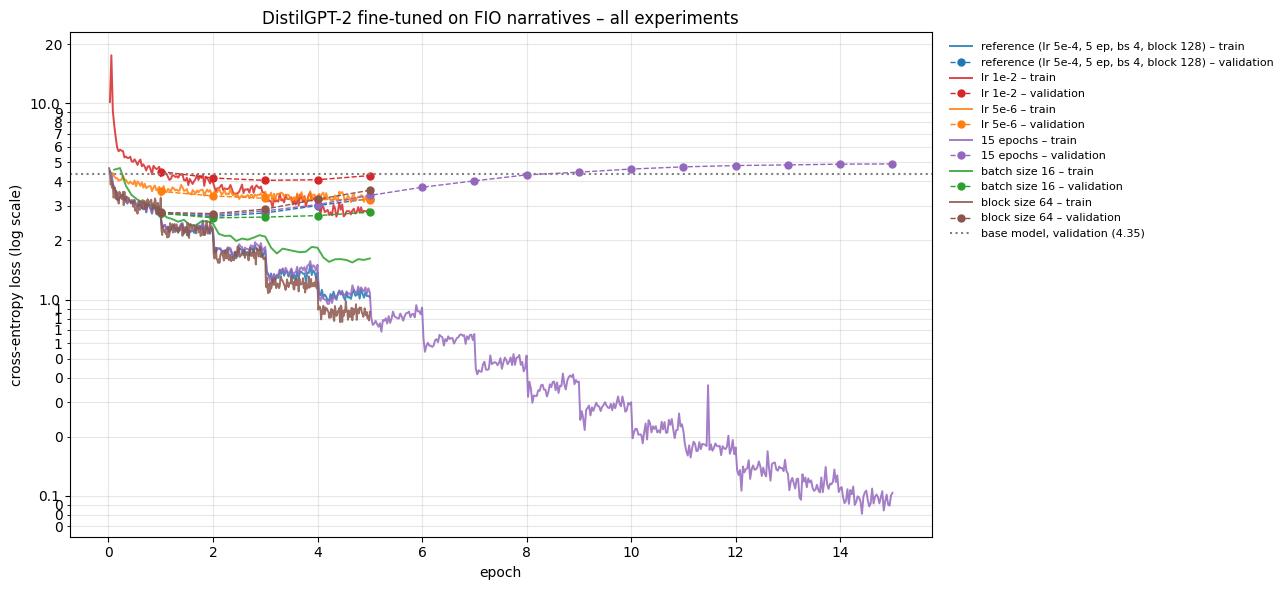

In [10]:
COLORS = {"reference": "#1f77b4", "lr_high": "#d62728", "lr_low": "#ff7f0e", "epochs_15": "#9467bd",
          "batch_16": "#2ca02c", "block_64": "#8c564b"}
LABELS = {"reference": "reference (lr 5e-4, 5 ep, bs 4, block 128)", "lr_high": "lr 1e-2",
          "lr_low": "lr 5e-6", "epochs_15": "15 epochs", "batch_16": "batch size 16", "block_64": "block size 64"}

from matplotlib.ticker import ScalarFormatter
fig, ax = plt.subplots(figsize=(13, 6))
for name, r in results.items():
    tr_df, ev_df = pd.DataFrame(r["train"]), pd.DataFrame(r["eval"])
    ax.plot(tr_df.epoch, tr_df.loss.clip(upper=50), color=COLORS[name], lw=1.4, alpha=0.85,
            label=f"{LABELS[name]} – train")
    if len(ev_df):
        ax.plot(ev_df.epoch, ev_df.loss.clip(upper=50), "o--", color=COLORS[name], ms=5, lw=1,
                label=f"{LABELS[name]} – validation")
ax.axhline(base_val_loss, color="grey", ls=":", lw=1.5, label=f"base model, validation ({base_val_loss:.2f})")
ax.set_yscale("log")
for axis in (ax.yaxis.set_major_formatter, ax.yaxis.set_minor_formatter):
    f = ScalarFormatter(); f.set_scientific(False); axis(f)
ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss (log scale)")
ax.set_title("DistilGPT-2 fine-tuned on FIO narratives – all experiments")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.savefig(f"{OUT}/all_loss_curves.png", dpi=150); plt.show()

### 5.2 Results table and diagnosis
Perplexity = e^(validation loss): roughly how many equally likely next tokens the model is choosing between –
lower is better. Each run is labelled automatically from **both** its training and validation curves:
* **diverged** – the training loss blew up: at some point it rose above 1.5× the base model's loss (or became NaN),
  i.e. the updates were large enough to push the model far *away* from a good solution;
* **overfit** – the validation loss rose by more than 5% after its best epoch, while the training loss kept falling;
* **underfit** – the validation loss was still falling at the last epoch and the training loss was no lower than
  the validation loss (no train/validation gap): the model had not yet learned what it could;
* otherwise **good fit**.

*Note:* the `block_64` validation loss is computed on 64-token blocks, so each prediction sees less context and its
loss is naturally a little higher; compare its curve shape rather than its absolute value.

In [11]:
rows = []
for name, r in results.items():
    ev = np.array([e["loss"] for e in r["eval"]], dtype=float)
    finite = np.isfinite(ev)
    best = float(ev[finite].min()) if finite.any() else float("nan")
    best_ep = int(np.nanargmin(np.where(finite, ev, np.inf))) + 1 if finite.any() else None
    final = float(ev[-1])
    tl = np.array([t["loss"] for t in r["train"]], dtype=float)
    if not np.isfinite(tl).all() or not np.isfinite(final) or np.nanmax(tl) > 1.5 * base_val_loss:
        verdict = "diverged"
    elif final > best * 1.05 and tl[-1] < tl[0]:
        verdict = "overfit"
    elif len(ev) > 1 and ev[-1] < ev[-2] and tl[-1] >= 0.98 * final:
        verdict = "underfit"
    else:
        verdict = "good fit"
    c = r["config"]
    rows.append({"run": name, "lr": c["lr"], "epochs": c["epochs"], "batch": c["batch_size"],
                 "block": c["block_size"], "steps": r["steps"], "peak train loss": float(np.nanmax(tl)),
                 "final train loss": r["train"][-1]["loss"],
                 "best val loss": best, "best epoch": best_ep, "final val loss": final,
                 "final val perplexity": math.exp(min(final, 50)) if np.isfinite(final) else float("inf"),
                 "minutes": r["seconds"] / 60,
                 "diagnosis": verdict})
table = pd.DataFrame(rows).set_index("run")
table.loc["base (no fine-tuning)"] = [np.nan, np.nan, np.nan, 128, 0, np.nan, np.nan, base_val_loss, np.nan,
                                      base_val_loss, math.exp(base_val_loss), 0, "—"]
display(table.style.format({"lr": "{:.0e}", "peak train loss": "{:.2f}", "final train loss": "{:.3f}", "best val loss": "{:.3f}",
                            "final val loss": "{:.3f}", "final val perplexity": "{:.1f}", "minutes": "{:.1f}"},
                           na_rep="—"))
table.to_csv(f"{OUT}/experiment_results.csv")

,lr,epochs,batch,block,steps,peak train loss,final train loss,best val loss,best epoch,final val loss,final val perplexity,minutes,diagnosis
run,,,,,,,,,,,,,
reference,5e-04,5.000000,4.000000,128,900,4.50,1.028,2.652,2.000000,3.267,26.2,1.0,overfit
lr_high,1e-02,5.000000,4.000000,128,900,17.58,2.698,4.050,3.000000,4.283,72.5,0.9,diverged
lr_low,5e-06,5.000000,4.000000,128,900,4.44,3.241,3.221,5.000000,3.221,25.1,0.9,underfit
epochs_15,5e-04,15.000000,4.000000,128,2700,4.50,0.103,2.696,2.000000,4.911,135.8,2.7,overfit
batch_16,5e-04,5.000000,16.000000,128,225,4.68,1.619,2.608,2.000000,2.790,16.3,0.6,overfit
block_64,5e-04,5.000000,4.000000,64,1800,4.67,0.864,2.740,2.000000,3.604,36.8,1.4,overfit
base (no fine-tuning),—,—,—,128,0,—,—,4.354,—,4.354,77.8,0.0,—


### 5.3 Side-by-side generation – same prompt, every model
Every model continues the same prompt with the same decoding settings (nucleus sampling, top-p 0.9, temperature
0.8, 70 new tokens) and the **same random seed**, so differences come from the weights, not from chance.
The prompt is a typical opening of a field report.

In [12]:
PROMPT = "On patrol in the area, officers observed"
GEN = dict(max_new_tokens=70, do_sample=True, top_p=0.9, temperature=0.8, repetition_penalty=1.1,
           pad_token_id=tokenizer.eos_token_id)

@torch.no_grad()
def generate(model, prompt=PROMPT, seed=SEED):
    model.to(device).eval()
    torch.manual_seed(seed)
    enc = tokenizer(prompt, return_tensors="pt").to(device)
    try:
        out = model.generate(**enc, **GEN)
        text = tokenizer.decode(out[0][enc["input_ids"].shape[1]:], skip_special_tokens=True)
        text = " ".join(text.split()) or "[empty output]"
    except RuntimeError as e:                 # a diverged model can have inf/NaN probabilities
        text = f"[generation failed – the model's probabilities became inf/NaN: {str(e)[:80]}]"
    model.to("cpu")
    return text

generations = {"base (no fine-tuning)": generate(base_model)}
for name in results:
    generations[name] = generate(models[name])

gen_df = pd.DataFrame({"model": list(generations), "continuation": list(generations.values())})
gen_df["diagnosis"] = gen_df.model.map(table["diagnosis"]).fillna("—")
display(gen_df.set_index("model"))
gen_df.to_csv(f"{OUT}/generations.csv", index=False)

,continuation,diagnosis
model,,
base (no fine-tuning),"two males entering a vehicle and one male driving through it. When an officer reached for his weapon oncoming traffic when he saw him enter, they began to pull out their guns,"" said Kadeh Khurshan...",—
reference,"a male later identified as [REDACTED] sitting on the steps of [REDACTED] Washington st in front of the Dunkin Donuts located at [REDACTED] [ADDRESS], while also following officer's instructions to...",overfit
lr_high,MA REG [PERSON] (Z429) and a CJIS inquiry of the intersection of [REDACTED] at [ADDRESS] Officers conducted a red hoodie) [REDACTED] Officers were aware of the passenger seat of [REDACTED] [REDACT...,diverged
lr_low,two males wearing a blue sweater with matching brown jeans and grey sneakers walking towards it. Officers were advised to enter at approximately 3:50 pm on foot for identification of any individua...,underfit
epochs_15,a small group of juveniles. Among them were [REDACTED] and [REDACTED] Officers were aware that [REDACTED] has a curfew at 8pm as of the first week of May.,overfit
batch_16,"two males (one male who matched that description) exiting [REDACTED] [ADDRESS], on foot towards Brewer Fountain. Officers stopped both males and briefly detained them in handcuffs. The males conti...",overfit
block_64,two males speaking to the officers and one was identified as [REDACTED] DOB: [REDACTED] stated that he was just visiting a friend. Officers conducted a CJIS inquiry of both parties which revealed ...,overfit


In [13]:
# The same comparison as plain text, easier to read and quote
print(f"PROMPT: {PROMPT}\n")
for name, text in generations.items():
    print(f"── {name} [{gen_df.set_index('model').loc[name, 'diagnosis']}]")
    print(f"   {PROMPT} {text}\n")

PROMPT: On patrol in the area, officers observed

── base (no fine-tuning) [—]
   On patrol in the area, officers observed two males entering a vehicle and one male driving through it. When an officer reached for his weapon oncoming traffic when he saw him enter, they began to pull out their guns," said Kadeh Khurshani, acting police chief of New Delhi. The driver then approached them with another handgun before pulling into a vacant SUV where he was

── reference [overfit]
   On patrol in the area, officers observed a male later identified as [REDACTED] sitting on the steps of [REDACTED] Washington st in front of the Dunkin Donuts located at [REDACTED] [ADDRESS], while also following officer's instructions to leave the area. Upon seeing this individual, officers immediately placed him under arrest and transported him to District B3 for further medical attention.

── lr_high [diverged]
   On patrol in the area, officers observed MA REG [PERSON] (Z429) and a CJIS inquiry of the intersec

### 5.4 Facts to use in the reflection
A quick summary of what the experiments showed, taken from the table above.

In [14]:
t = table.drop(index="base (no fine-tuning)")
ref = t.loc["reference"]
print(f"Base model validation perplexity: {math.exp(base_val_loss):.1f}")
print(f"Reference: validation perplexity {ref['final val perplexity']:.1f} "
      f"(best at epoch {ref['best epoch']}), {ref['minutes']:.1f} min")
for name, r in t.iterrows():
    if name == "reference":
        continue
    print(f"{name:<10} → {r['diagnosis']:<9} | peak train loss {r['peak train loss']:.2f} | best val loss "
          f"{r['best val loss']:.3f} at epoch {r['best epoch']}, final {r['final val loss']:.3f} "
          f"(reference {ref['final val loss']:.3f})")
ep = results["epochs_15"]["eval"]
print("\n15-epoch run, validation loss per epoch:", [round(e["loss"], 3) for e in ep])

Base model validation perplexity: 77.8
Reference: validation perplexity 26.2 (best at epoch 2.0), 1.0 min
lr_high    → diverged  | peak train loss 17.58 | best val loss 4.050 at epoch 3.0, final 4.283 (reference 3.267)
lr_low     → underfit  | peak train loss 4.44 | best val loss 3.221 at epoch 5.0, final 3.221 (reference 3.267)
epochs_15  → overfit   | peak train loss 4.50 | best val loss 2.696 at epoch 2.0, final 4.911 (reference 3.267)
batch_16   → overfit   | peak train loss 4.68 | best val loss 2.608 at epoch 2.0, final 2.790 (reference 3.267)
block_64   → overfit   | peak train loss 4.67 | best val loss 2.740 at epoch 2.0, final 3.604 (reference 3.267)

15-epoch run, validation loss per epoch: [2.77, 2.696, 2.829, 3.048, 3.394, 3.734, 4.026, 4.319, 4.459, 4.625, 4.745, 4.819, 4.855, 4.898, 4.911]


### 5.5 Save the best model for deployment
The run with the lowest final validation loss that did not diverge is saved (its weights from the last epoch),
together with the tokenizer, the
results table, the loss plot and the generations. Download `fio_lm_model.zip` (for Hugging Face) and
`fio_lm_results.zip` (for the GitHub repository of the Streamlit app).

In [15]:
import shutil, json
candidates = table.drop(index="base (no fine-tuning)")
candidates = candidates[candidates.diagnosis != "diverged"]
best_run = candidates["final val loss"].astype(float).idxmin()
print(f"Best run: {best_run} – final validation loss {candidates.loc[best_run, 'final val loss']:.3f}, "
      f"perplexity {candidates.loc[best_run, 'final val perplexity']:.1f}")

SAVE_DIR = "fio_lm_model"
models[best_run].save_pretrained(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
with open(f"{SAVE_DIR}/training_info.json", "w") as fh:
    json.dump({"base_model": MODEL_NAME, "run": best_run, "config": results[best_run]["config"],
               "final_val_loss": float(candidates.loc[best_run, "final val loss"]),
               "base_val_loss": base_val_loss, "corpus": "600 redacted Boston FIO narratives (2024)"}, fh, indent=1)
shutil.make_archive("fio_lm_model", "zip", SAVE_DIR)

RES_DIR = "fio_lm_results"; os.makedirs(RES_DIR, exist_ok=True)
for f in ["experiment_results.csv", "generations.csv", "all_loss_curves.png"]:
    shutil.copy(f"{OUT}/{f}", RES_DIR)
loss_log = [{"run": n, "kind": k, **row} for n, r in results.items() for k in ("train", "eval") for row in r[k]]
pd.DataFrame(loss_log).to_csv(f"{RES_DIR}/loss_log.csv", index=False)
shutil.make_archive("fio_lm_results", "zip", RES_DIR)
print("Created fio_lm_model.zip and fio_lm_results.zip")
try:
    from google.colab import files
    files.download("fio_lm_model.zip"); files.download("fio_lm_results.zip")
except Exception:
    pass

Best run: batch_16 – final validation loss 2.790, perplexity 16.3


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Created fio_lm_model.zip and fio_lm_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Reflection (200–300 words)
*Write this in your own words from the plot, the table, the facts in 5.4 and the generated text. Delete these
guiding questions before submitting.*

* **Fit:** Which run diverged, which underfit and which overfit? *How could you tell* – what did the training and
  validation curves do (e.g. loss rising instead of falling, a flat curve, a widening gap between train and
  validation)?
* **Hyperparameters:** What did batch size 16 and block size 64 change compared with the reference, and why?
* **More compute or data:** What would you change – for example the full 4,600-narrative corpus, early stopping
  on validation loss, a learning-rate sweep or warm-up, a larger model such as GPT-2 medium, or several seeds?
* **Qualitative observation:** In *specific* ways, how did the fine-tuned text differ from the base model's – e.g.
  police abbreviations (MV, F/A, FIO), placeholders such as [REDACTED] or [ADDRESS], report structure, tone? What
  did the diverged and underfit models produce?
* **Responsibility:** the outputs are synthetic and could reproduce demographic descriptors from the source data.

> *Your reflection here (200–300 words).*